In [59]:
import matplotlib.pyplot as plt
import pandas as pd
import plotly.graph_objects as go
from sklearn.cluster import KMeans
import numpy as np

(553, 555, 3)


(np.float64(-0.5), np.float64(554.5), np.float64(552.5), np.float64(-0.5))

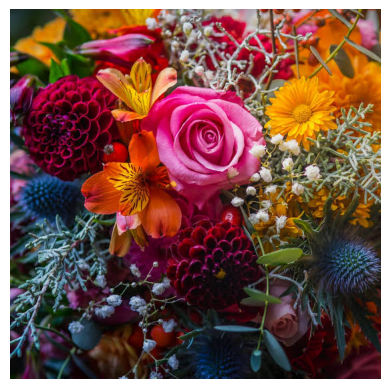

In [60]:
img = plt.imread('images/images.jpeg')  
print(img.shape)  # (height, width, channels)
plt.imshow(img)
plt.axis('off')

In [61]:
img_flat = img.reshape(img.shape[0]*img.shape[1], 3)  # Flatten the image to a 2D array of pixels
img_flat[:5,:]  # Show the first 5 pixels

array([[30, 45, 42],
       [30, 45, 42],
       [30, 45, 42],
       [30, 45, 42],
       [30, 45, 42]], dtype=uint8)

In [62]:
img_flat.shape

(306915, 3)

In [63]:
img_flat_df = pd.DataFrame(img_flat, columns=['r', 'g', 'b'])
img_flat_df.head()  # Show the first 5 rows of the DataFrame

,r,g,b
0,30,45,42
1,30,45,42
2,30,45,42
3,30,45,42
4,30,45,42


In [64]:
trace = go.Scatter3d(x = img_flat_df.r,
                     y = img_flat_df.g,
                     z = img_flat_df.b,
                     mode = 'markers',
                     marker = dict(size=1, 
                                   color =['rgb({},{},{})'.format(r,g,b) for r,g,b in zip(img_flat_df.r.values,
                                                                                          img_flat_df.g.values,
                                                                                            img_flat_df.b.values)],
                                                                                            opacity=0.5))
data = [trace]
layout = go.Layout(margin=dict(l=0, r=0, b=0, t=0))
fig = go.Figure(data=data, layout=layout)
fig.update_layout(scene = dict(xaxis_title='R', 
                                yaxis_title='G', 
                                zaxis_title='B'))
fig.show()

In [65]:
kmeans = KMeans(n_clusters = 1, random_state = 67).fit(img_flat)


(np.float64(-0.5), np.float64(554.5), np.float64(552.5), np.float64(-0.5))

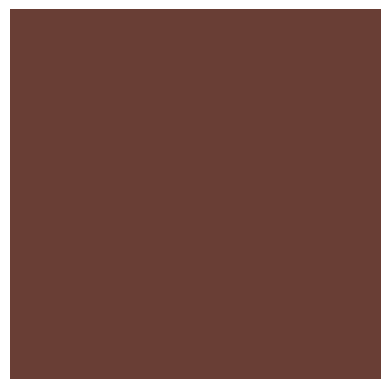

In [66]:
img_flat1 = img_flat.copy()

for i in np.unique(kmeans.labels_):
    img_flat1[kmeans.labels_ == i, :] = kmeans.cluster_centers_[i]

img1 = img_flat1.reshape(img.shape)

plt.imshow(img1)
plt.axis('off')

In [67]:
print('cluster centers:', kmeans.cluster_centers_)

cluster centers: [[105.44088103  62.32682013  53.28963394]]


In [68]:
trace = go.Scatter3d(x = img_flat_df.r,
                     y = img_flat_df.g,
                     z = img_flat_df.b,
                     mode = 'markers',
                     marker = dict(size=1, 
                                   color =['rgb({},{},{})'.format(r,g,b) for r,g,b in zip(img_flat_df.r.values,
                                                                                          img_flat_df.g.values,
                                                                                            img_flat_df.b.values)],
                                                                                            opacity=0.5))
data = [trace]
layout = go.Layout(margin=dict(l=0, r=0, b=0, t=0))
fig = go.Figure(data=data, layout=layout)
fig.update_layout(scene = dict(xaxis_title='R', 
                                yaxis_title='G', 
                                zaxis_title='B'))
centroid = kmeans.cluster_centers_[0].tolist()

fig.show()

In [69]:
kmeans10 = KMeans(n_clusters = 10, random_state = 67).fit(img_flat)
np.unique(kmeans10.labels_)  # Check the number of unique labels

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=int32)

In [70]:
def show_swatch(RGB_value):
    R, G, B = RGB_value
    rgb = [[np.array([R,G,B]).astype('uint8')]]
    plt.figure()
    plt.imshow(rgb)
    plt.axis('off');

In [71]:
centers = kmeans10.cluster_centers_

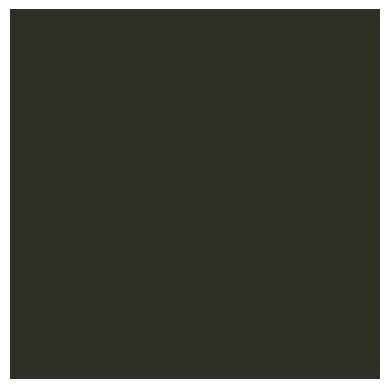

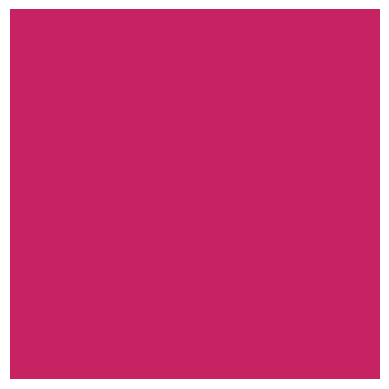

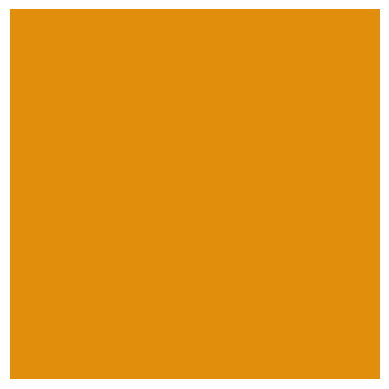

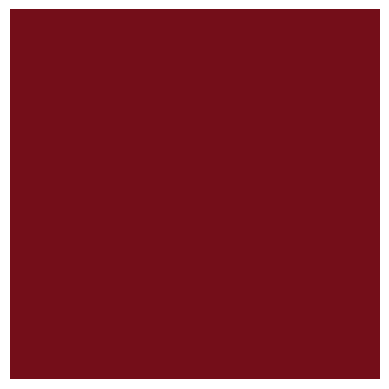

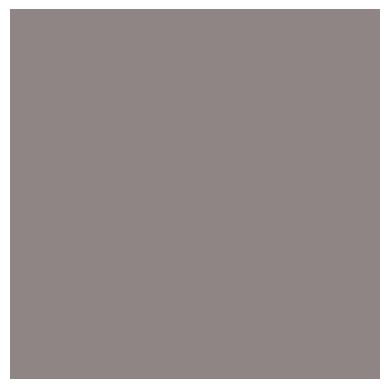

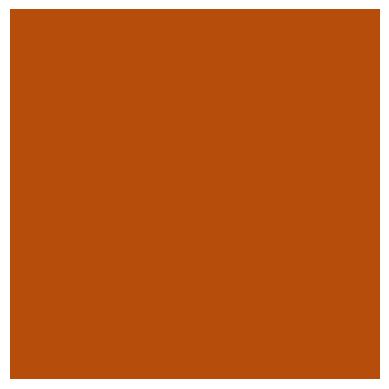

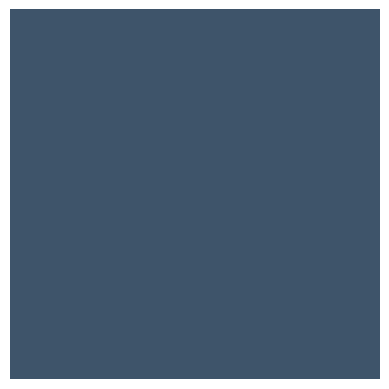

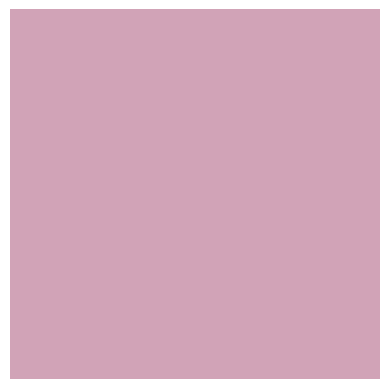

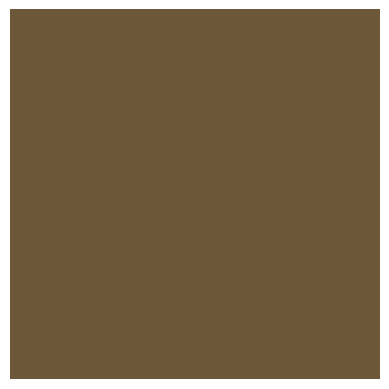

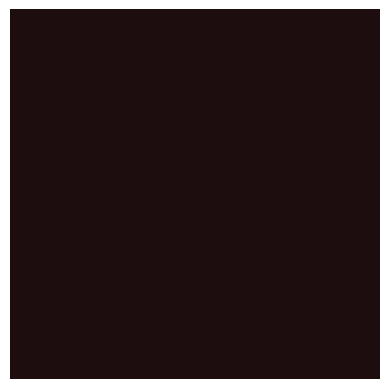

In [72]:
for pixel in centers:
    show_swatch(pixel)

In [73]:
def cluster_image(k, img = img):
    img_flat = img.reshape(img.shape[0]*img.shape[1], 3)
    kmeans = KMeans(n_clusters = k, random_state = 67).fit(img_flat)
    new_img = img_flat.copy()
    for i in np.unique(kmeans.labels_):
        new_img[kmeans.labels_ == i, :] = kmeans.cluster_centers_[i]
    new_img = new_img.reshape(img.shape)
    return plt.imshow(new_img), plt.axis('off');

(<matplotlib.image.AxesImage at 0x30bdb8920>,
 (np.float64(-0.5), np.float64(554.5), np.float64(552.5), np.float64(-0.5)))

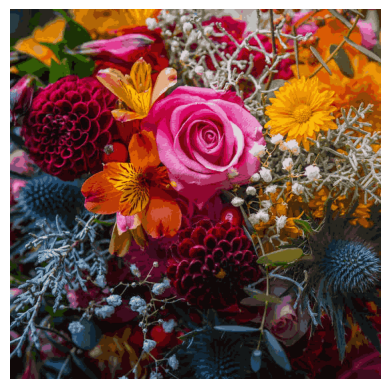

In [74]:
cluster_image(50)

In [75]:
img_flat_df['cluster'] = kmeans10.labels_

series_conversion = {i: 'rgb({},{},{})'.format(*center.astype('uint8'))
                     for i, center in enumerate(kmeans10.cluster_centers_)}
series_conversion

{0: 'rgb(48,47,38)',
 1: 'rgb(199,35,98)',
 2: 'rgb(225,142,13)',
 3: 'rgb(116,14,25)',
 4: 'rgb(142,133,132)',
 5: 'rgb(182,77,10)',
 6: 'rgb(62,84,106)',
 7: 'rgb(209,163,183)',
 8: 'rgb(108,88,56)',
 9: 'rgb(30,13,15)'}

In [76]:
img_flat_df['cluster'] = pd.Series(kmeans10.labels_).map(series_conversion)
img_flat_df.head()

,r,g,b,cluster
0,30,45,42,"rgb(48,47,38)"
1,30,45,42,"rgb(48,47,38)"
2,30,45,42,"rgb(48,47,38)"
3,30,45,42,"rgb(48,47,38)"
4,30,45,42,"rgb(48,47,38)"


In [77]:
trace = go.Scatter3d(x = img_flat_df.r,
                     y = img_flat_df.g,
                     z = img_flat_df.b,
                     mode='markers',
                     marker=dict(size=1,
                                 color=img_flat_df.cluster,
                                 opacity=1))

data = trace

layout = go.Layout(margin=dict(l=0,
                               r=0,
                               b=0,
                               t=0))

fig = go.Figure(data=data, layout=layout)
fig.show()

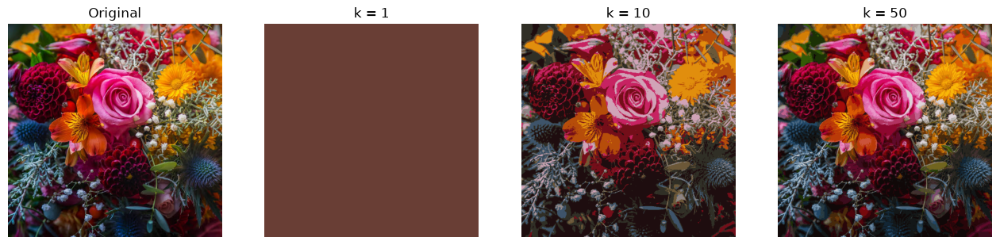

In [78]:
# Comparison of K-Means Clustering for Image Compression
plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(img)
plt.axis('off')
plt.title('Original')

for i, k in enumerate([1, 10, 50]):
    plt.subplot(1, 4, i + 2)
    cluster_image(k)
    plt.title(f'k = {k}')

plt.savefig('images/comparison.jpg', bbox_inches='tight')

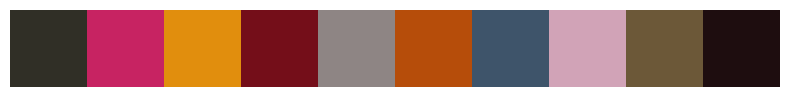

In [79]:
# K = 10 cluster centers pallete
plt.figure(figsize=(10, 1))
plt.imshow([centers.astype('uint8')])
plt.axis('off')
plt.savefig('images/palette_k10.png', bbox_inches='tight')